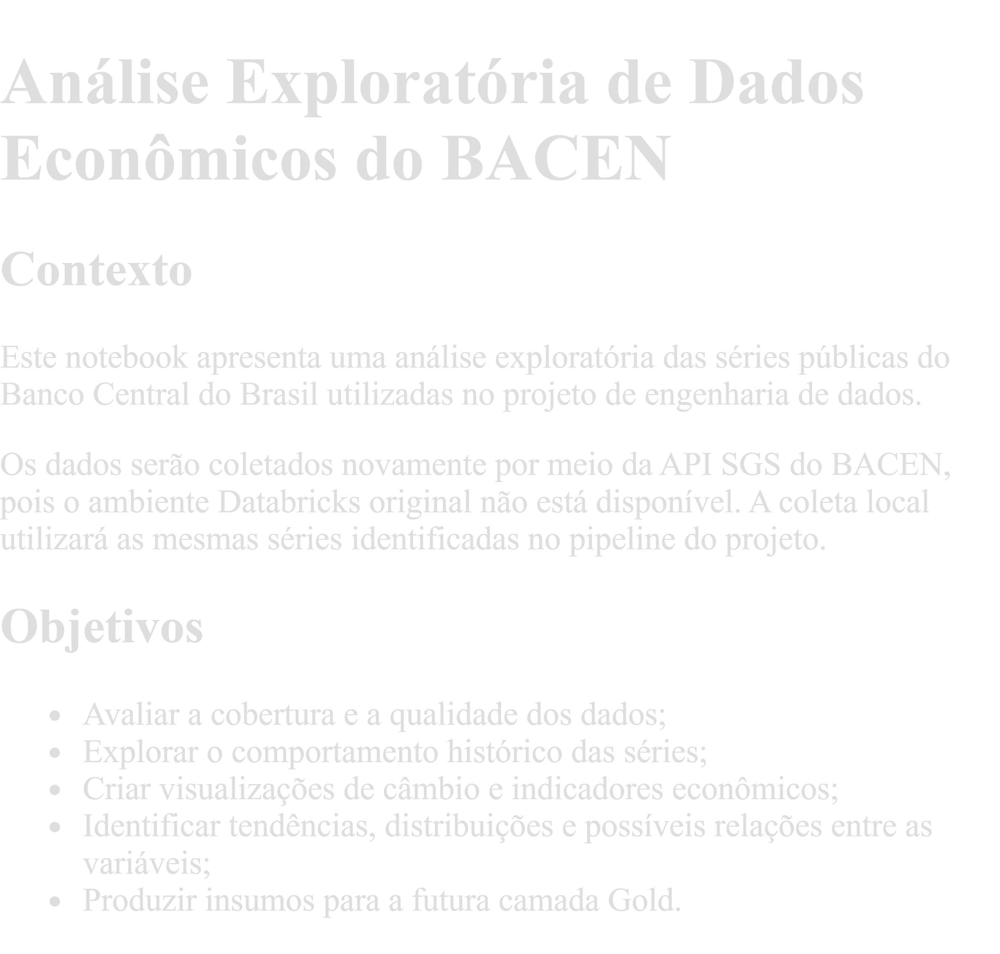

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [2]:
# Código SGS 1: cotação do dólar em relação ao real
url_teste = (
    "https://api.bcb.gov.br/dados/serie/"
    "bcdata.sgs.1/dados/ultimos/10?formato=json"
)

resposta = requests.get(url_teste, timeout=60)

print("Status da requisição:", resposta.status_code)

Status da requisição: 200


In [3]:
dados_teste = resposta.json()

df_teste = pd.DataFrame(dados_teste)

df_teste

,data,valor
0,09/10/2026,4.9892
1,13/10/2026,5.0096
2,14/10/2026,5.0441
3,15/10/2026,5.0521
4,16/10/2026,5.0826
5,19/10/2026,5.0564
6,20/10/2026,5.0140
7,21/10/2026,5.0277
8,22/10/2026,5.0383
9,23/10/2026,5.0377


In [4]:
print("Quantidade de linhas e colunas:", df_teste.shape)

print("\nNomes das colunas:")
print(df_teste.columns.tolist())

print("\nTipos das colunas:")
df_teste.info()

Quantidade de linhas e colunas: (10, 2)

Nomes das colunas:
['data', 'valor']

Tipos das colunas:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   data    10 non-null     str  
 1   valor   10 non-null     str  
dtypes: str(2)
memory usage: 292.0 bytes


In [5]:
df_teste.head()

,data,valor
0,09/10/2026,4.9892
1,13/10/2026,5.0096
2,14/10/2026,5.0441
3,15/10/2026,5.0521
4,16/10/2026,5.0826


In [7]:
# Criar uma cópia para preservar os dados originais
df_teste_tratado = df_teste.copy()

# Converter a coluna data de texto para data
df_teste_tratado["data"] = pd.to_datetime(
    df_teste_tratado["data"],
    format="%d/%m/%Y"
)

# Converter a coluna valor de texto para número decimal
df_teste_tratado["valor"] = pd.to_numeric(
    df_teste_tratado["valor"],
    errors="coerce"
)

df_teste_tratado.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   data    10 non-null     datetime64[us]
 1   valor   10 non-null     float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 292.0 bytes


In [8]:
df_teste_tratado

,data,valor
0,2026-10-09,4.9892
1,2026-10-13,5.0096
2,2026-10-14,5.0441
3,2026-10-15,5.0521
4,2026-10-16,5.0826
5,2026-10-19,5.0564
6,2026-10-20,5.0140
7,2026-10-21,5.0277
8,2026-10-22,5.0383
9,2026-10-23,5.0377


In [9]:
print("Quantidade de registros:", len(df_teste_tratado))

print("\nValores nulos por coluna:")
print(df_teste_tratado.isnull().sum())

print("\nQuantidade de linhas duplicadas:")
print(df_teste_tratado.duplicated().sum())

Quantidade de registros: 10

Valores nulos por coluna:
data     0
valor    0
dtype: int64

Quantidade de linhas duplicadas:
0


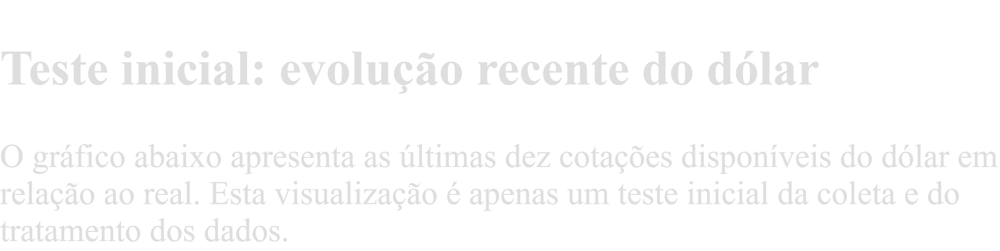

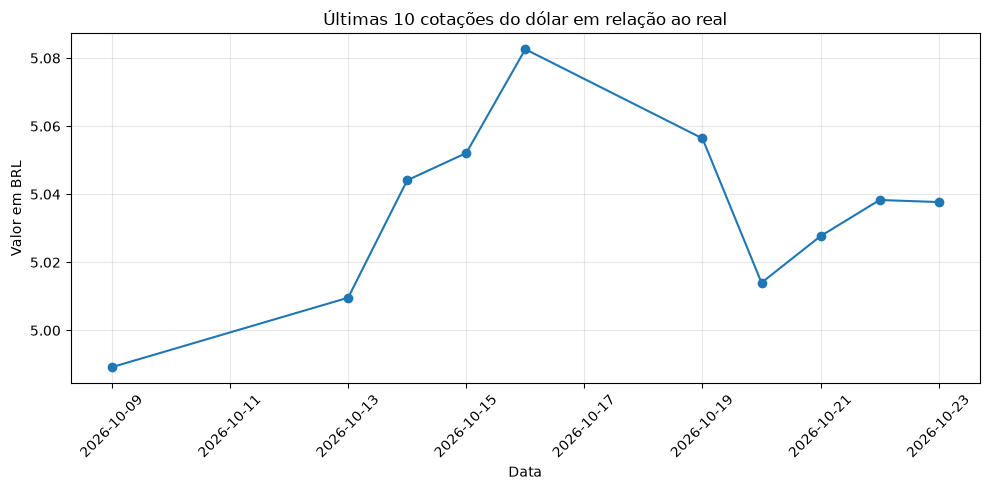

In [12]:
# Ordenar os registros da data mais antiga para a mais recente
df_teste_tratado = df_teste_tratado.sort_values("data")

# Criar a visualização
plt.figure(figsize=(10, 5))

plt.plot(
    df_teste_tratado["data"],
    df_teste_tratado["valor"],
    marker="o"
)

plt.title("Últimas 10 cotações do dólar em relação ao real")
plt.xlabel("Data")
plt.ylabel("Valor em BRL")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

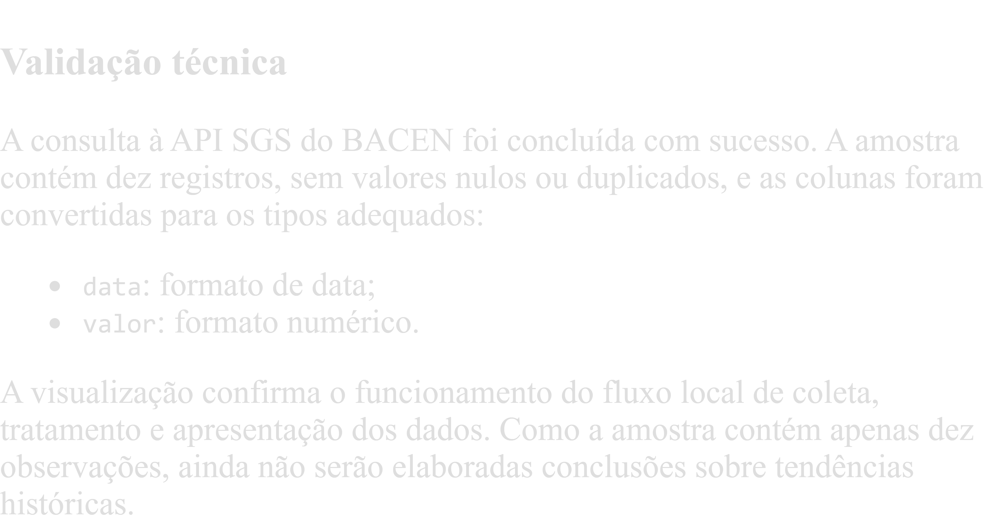

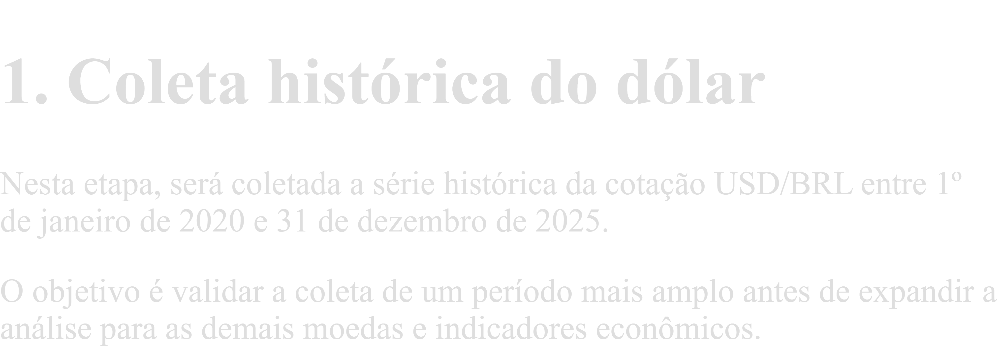

In [13]:
# Configuração da série histórica do dólar

codigo_serie = 1
data_inicial = "01/01/2020"
data_final = "31/12/2025"

url_dolar_historico = (
    f"https://api.bcb.gov.br/dados/serie/"
    f"bcdata.sgs.{codigo_serie}/dados"
)

parametros = {
    "formato": "json",
    "dataInicial": data_inicial,
    "dataFinal": data_final
}

print("Série SGS:", codigo_serie)
print("Período:", data_inicial, "a", data_final)

Série SGS: 1
Período: 01/01/2020 a 31/12/2025


In [14]:
resposta_dolar = requests.get(
    url_dolar_historico,
    params=parametros,
    timeout=60
)

print("Status da requisição:", resposta_dolar.status_code)
print("URL consultada:", resposta_dolar.url)

Status da requisição: 200
URL consultada: https://api.bcb.gov.br/dados/serie/bcdata.sgs.1/dados?formato=json&dataInicial=01%2F01%2F2020&dataFinal=31%2F12%2F2025


In [15]:
dados_dolar = resposta_dolar.json()

df_dolar_raw = pd.DataFrame(dados_dolar)

print("Quantidade de registros recebidos:", len(df_dolar_raw))

df_dolar_raw.head()

Quantidade de registros recebidos: 1507


,data,valor
0,02/01/2020,4.0213
1,03/01/2020,4.0522
2,06/01/2020,4.0554
3,07/01/2020,4.0841
4,08/01/2020,4.0672


In [16]:
df_dolar_raw.tail()

,data,valor
1502,24/12/2025,5.5350
1503,26/12/2025,5.5413
1504,29/12/2025,5.5739
1505,30/12/2025,5.5024
1506,31/12/2025,5.5024


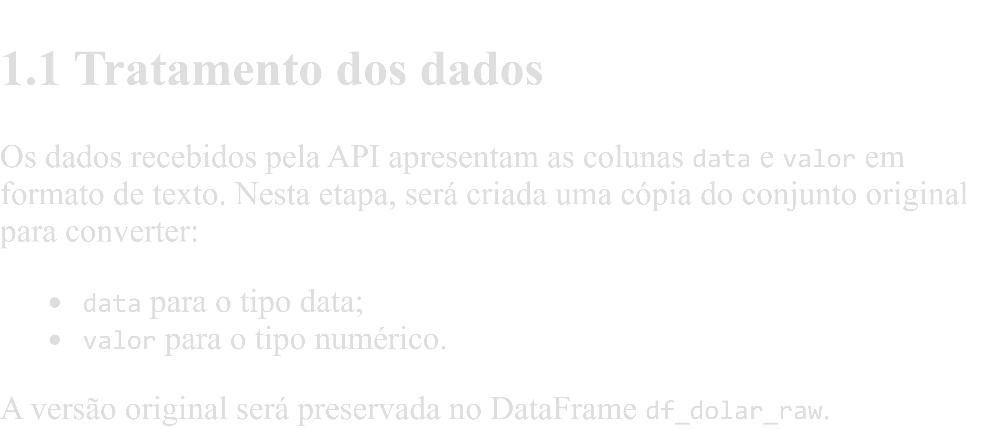

In [17]:
# Criar uma cópia para preservar os dados originais
df_dolar = df_dolar_raw.copy()

# Converter a data
df_dolar["data"] = pd.to_datetime(
    df_dolar["data"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Converter o valor
df_dolar["valor"] = pd.to_numeric(
    df_dolar["valor"],
    errors="coerce"
)

# Ordenar os registros por data
df_dolar = (
    df_dolar
    .sort_values("data")
    .reset_index(drop=True)
)

df_dolar.info()

<class 'pandas.DataFrame'>
RangeIndex: 1507 entries, 0 to 1506
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   data    1507 non-null   datetime64[us]
 1   valor   1507 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 23.7 KB


In [18]:
print("Primeiros registros:")
display(df_dolar.head())

print("Últimos registros:")
display(df_dolar.tail())

Primeiros registros:


,data,valor
0,2020-01-02,4.0213
1,2020-01-03,4.0522
2,2020-01-06,4.0554
3,2020-01-07,4.0841
4,2020-01-08,4.0672


Últimos registros:


,data,valor
1502,2025-12-24,5.5350
1503,2025-12-26,5.5413
1504,2025-12-29,5.5739
1505,2025-12-30,5.5024
1506,2025-12-31,5.5024


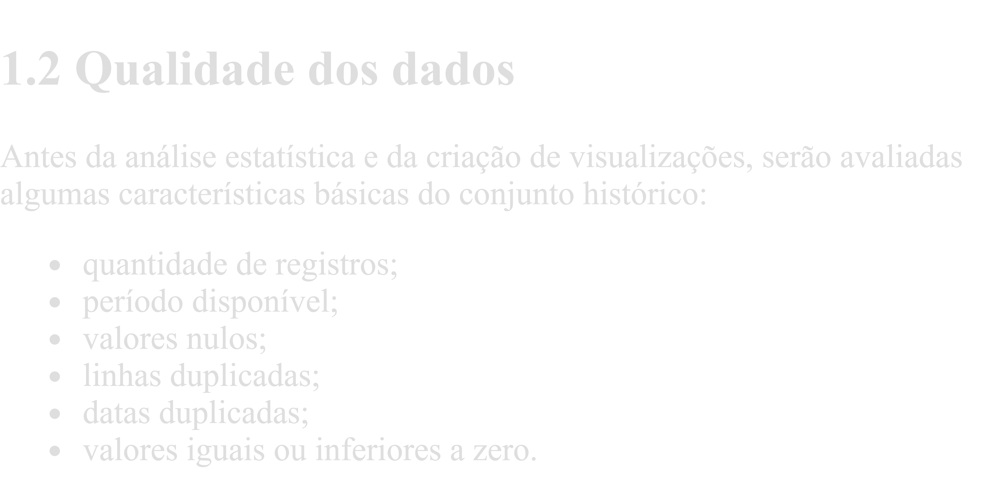

In [19]:
print("Quantidade de registros:", len(df_dolar))

print("\nPeríodo disponível:")
print("Data inicial:", df_dolar["data"].min())
print("Data final:", df_dolar["data"].max())

print("\nValores nulos por coluna:")
print(df_dolar.isnull().sum())

print("\nLinhas completamente duplicadas:")
print(df_dolar.duplicated().sum())

print("\nDatas duplicadas:")
print(df_dolar.duplicated(subset=["data"]).sum())

print("\nValores iguais ou inferiores a zero:")
print((df_dolar["valor"] <= 0).sum())

Quantidade de registros: 1507

Período disponível:
Data inicial: 2020-01-02 00:00:00
Data final: 2025-12-31 00:00:00

Valores nulos por coluna:
data     0
valor    0
dtype: int64

Linhas completamente duplicadas:
0

Datas duplicadas:
0

Valores iguais ou inferiores a zero:
0


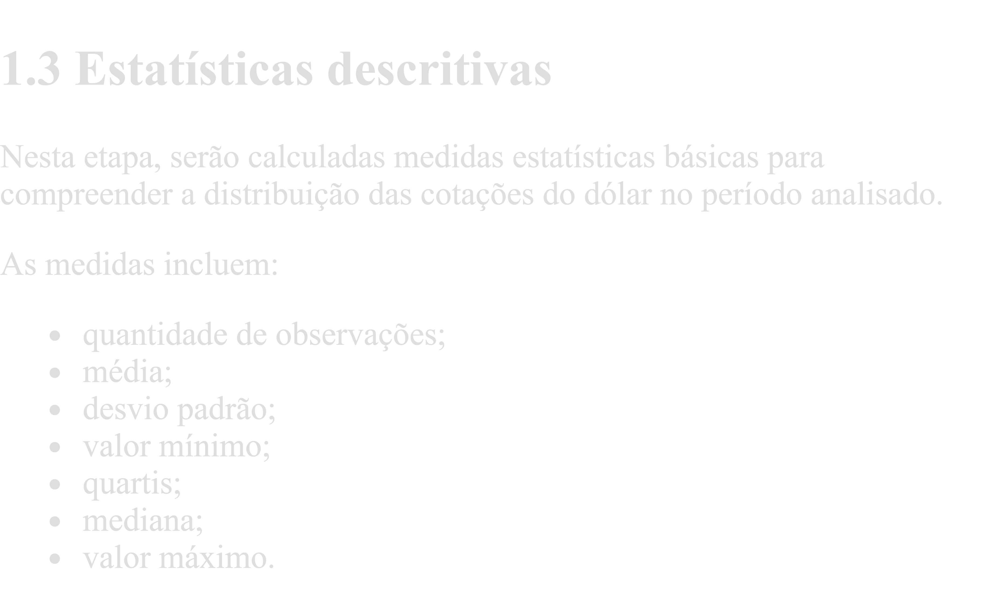

In [20]:
estatisticas_dolar = df_dolar["valor"].describe()

estatisticas_dolar

count    1507.000000
mean        5.282675
std         0.350876
min         4.021300
25%         5.060250
50%         5.293200
75%         5.521300
max         6.208600
Name: valor, dtype: float64

In [21]:
print(f"Quantidade de observações: {estatisticas_dolar['count']:.0f}")
print(f"Cotação média: R$ {estatisticas_dolar['mean']:.4f}")
print(f"Desvio padrão: R$ {estatisticas_dolar['std']:.4f}")
print(f"Menor cotação: R$ {estatisticas_dolar['min']:.4f}")
print(f"Primeiro quartil: R$ {estatisticas_dolar['25%']:.4f}")
print(f"Mediana: R$ {estatisticas_dolar['50%']:.4f}")
print(f"Terceiro quartil: R$ {estatisticas_dolar['75%']:.4f}")
print(f"Maior cotação: R$ {estatisticas_dolar['max']:.4f}")

Quantidade de observações: 1507
Cotação média: R$ 5.2827
Desvio padrão: R$ 0.3509
Menor cotação: R$ 4.0213
Primeiro quartil: R$ 5.0602
Mediana: R$ 5.2932
Terceiro quartil: R$ 5.5213
Maior cotação: R$ 6.2086


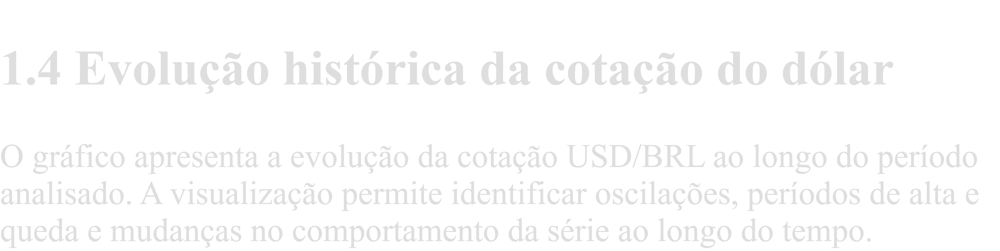

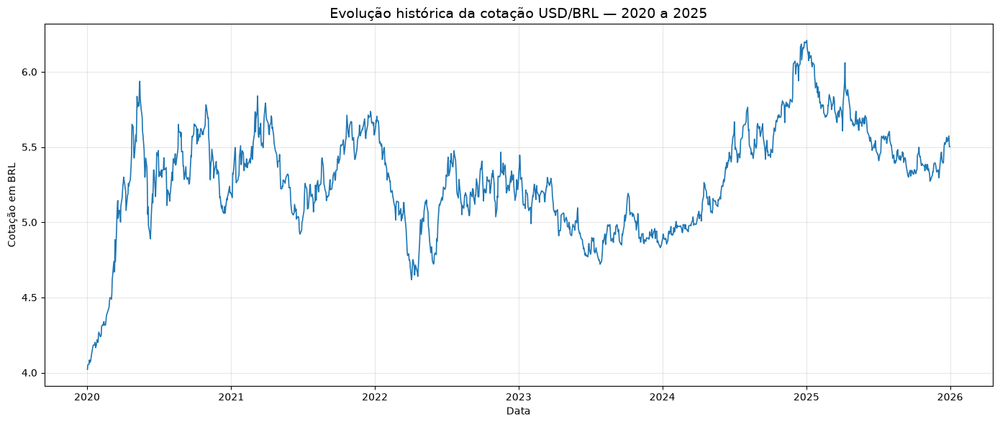

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_dolar["data"],
    df_dolar["valor"],
    linewidth=1.2,
    color="#1f77b4"
)

plt.title(
    "Evolução histórica da cotação USD/BRL — 2020 a 2025",
    fontsize=14
)

plt.xlabel("Data")
plt.ylabel("Cotação em BRL")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

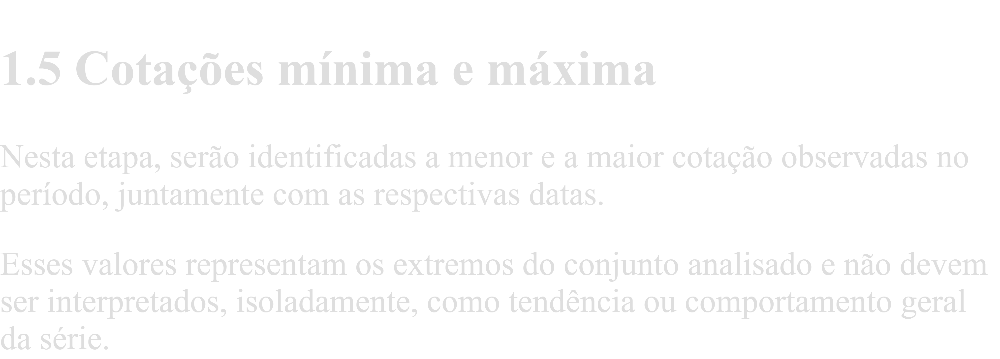

In [23]:
# Localizar os índices da menor e da maior cotação
indice_minimo = df_dolar["valor"].idxmin()
indice_maximo = df_dolar["valor"].idxmax()

# Recuperar os respectivos registros
registro_minimo = df_dolar.loc[indice_minimo]
registro_maximo = df_dolar.loc[indice_maximo]

print("Menor cotação do período")
print(f"Data: {registro_minimo['data']:%d/%m/%Y}")
print(f"Valor: R$ {registro_minimo['valor']:.4f}")

print("\nMaior cotação do período")
print(f"Data: {registro_maximo['data']:%d/%m/%Y}")
print(f"Valor: R$ {registro_maximo['valor']:.4f}")

Menor cotação do período
Data: 02/01/2020
Valor: R$ 4.0213

Maior cotação do período
Data: 02/01/2025
Valor: R$ 6.2086


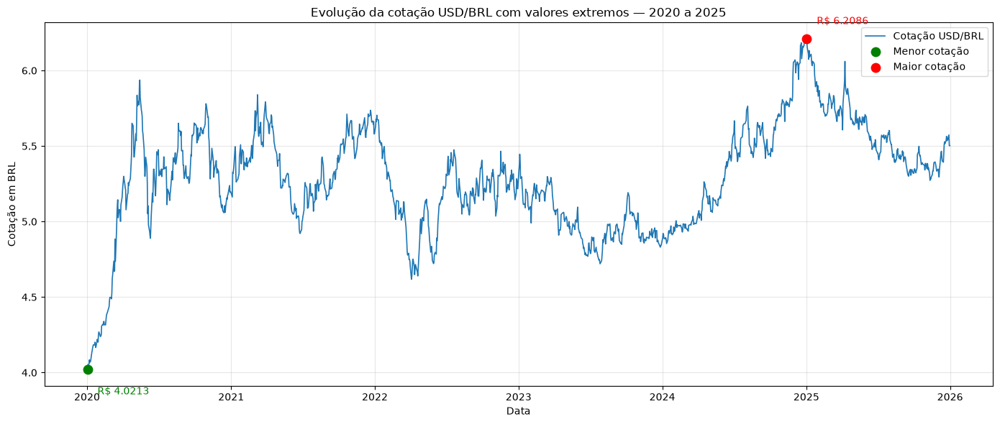

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_dolar["data"],
    df_dolar["valor"],
    linewidth=1.2,
    color="#1f77b4",
    label="Cotação USD/BRL"
)

plt.scatter(
    registro_minimo["data"],
    registro_minimo["valor"],
    color="green",
    s=80,
    label="Menor cotação",
    zorder=3
)

plt.scatter(
    registro_maximo["data"],
    registro_maximo["valor"],
    color="red",
    s=80,
    label="Maior cotação",
    zorder=3
)

plt.annotate(
    f"R$ {registro_minimo['valor']:.4f}",
    xy=(registro_minimo["data"], registro_minimo["valor"]),
    xytext=(10, -25),
    textcoords="offset points",
    color="green"
)

plt.annotate(
    f"R$ {registro_maximo['valor']:.4f}",
    xy=(registro_maximo["data"], registro_maximo["valor"]),
    xytext=(10, 15),
    textcoords="offset points",
    color="red"
)

plt.title("Evolução da cotação USD/BRL com valores extremos — 2020 a 2025")
plt.xlabel("Data")
plt.ylabel("Cotação em BRL")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

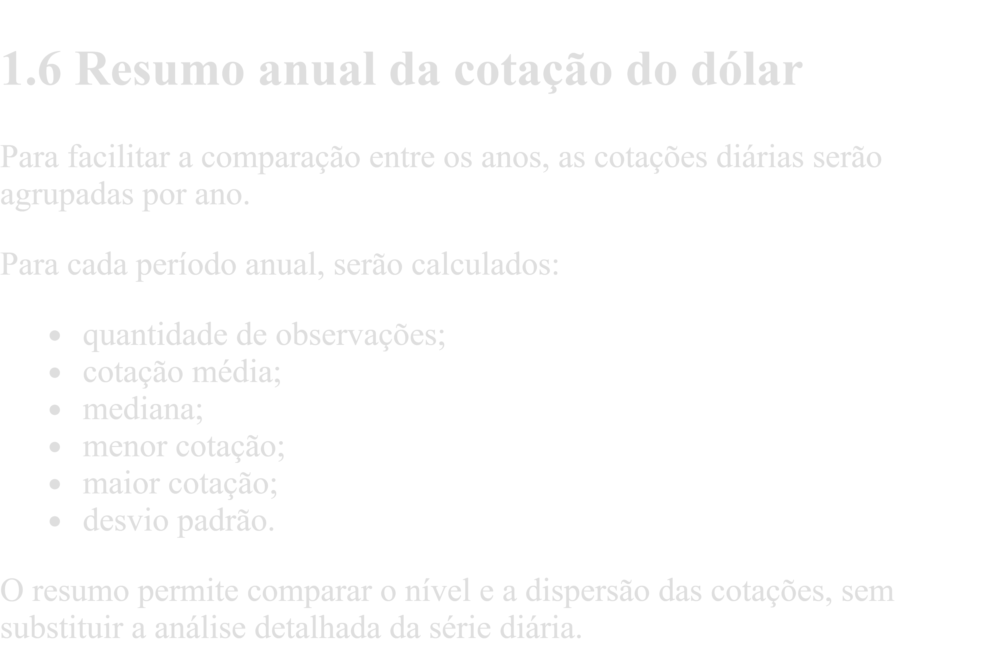

In [25]:
# Criar uma cópia para a análise anual
df_dolar_anual_base = df_dolar.copy()

# Extrair o ano da data
df_dolar_anual_base["ano"] = df_dolar_anual_base["data"].dt.year

df_dolar_anual_base.head()

,data,valor,ano
0,2020-01-02,4.0213,2020
1,2020-01-03,4.0522,2020
2,2020-01-06,4.0554,2020
3,2020-01-07,4.0841,2020
4,2020-01-08,4.0672,2020


In [26]:
resumo_anual_dolar = (
    df_dolar_anual_base
    .groupby("ano")
    .agg(
        observacoes=("valor", "count"),
        media=("valor", "mean"),
        mediana=("valor", "median"),
        minimo=("valor", "min"),
        maximo=("valor", "max"),
        desvio_padrao=("valor", "std")
    )
    .reset_index()
)

resumo_anual_dolar

,ano,observacoes,media,mediana,minimo,maximo,desvio_padrao
0,2020,251,5.157773,5.28540,4.0213,5.9372,0.470024
1,2021,251,5.395561,5.40240,4.9206,5.8397,0.209008
2,2022,251,5.165482,5.18840,4.6175,5.7042,0.223245
3,2023,249,4.995348,4.96780,4.7202,5.4459,0.148686
4,2024,253,5.392016,5.44120,4.8543,6.1991,0.360142
5,2025,252,5.585500,5.54345,5.2729,6.2086,0.212913


In [27]:
resumo_anual_exibicao = resumo_anual_dolar.copy()

colunas_numericas = [
    "media",
    "mediana",
    "minimo",
    "maximo",
    "desvio_padrao"
]

resumo_anual_exibicao[colunas_numericas] = (
    resumo_anual_exibicao[colunas_numericas].round(4)
)

resumo_anual_exibicao

,ano,observacoes,media,mediana,minimo,maximo,desvio_padrao
0,2020,251,5.1578,5.2854,4.0213,5.9372,0.4700
1,2021,251,5.3956,5.4024,4.9206,5.8397,0.2090
2,2022,251,5.1655,5.1884,4.6175,5.7042,0.2232
3,2023,249,4.9953,4.9678,4.7202,5.4459,0.1487
4,2024,253,5.3920,5.4412,4.8543,6.1991,0.3601
5,2025,252,5.5855,5.5434,5.2729,6.2086,0.2129


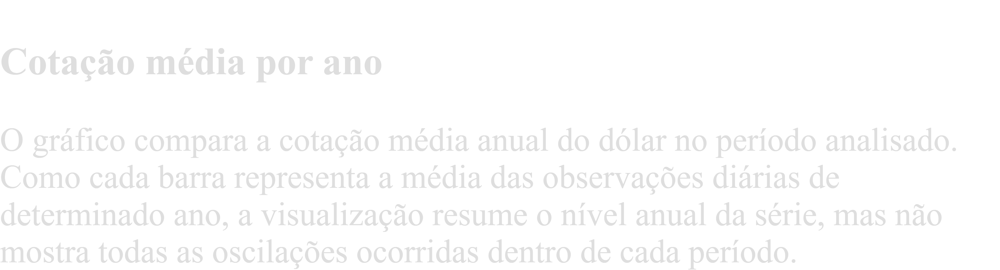

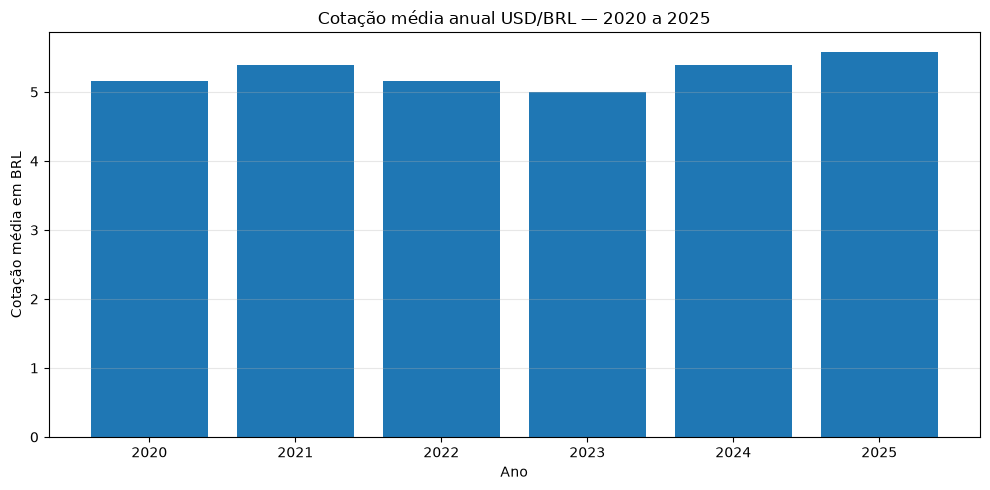

In [28]:
plt.figure(figsize=(10, 5))

plt.bar(
    resumo_anual_dolar["ano"].astype(str),
    resumo_anual_dolar["media"],
    color="#1f77b4"
)

plt.title("Cotação média anual USD/BRL — 2020 a 2025")
plt.xlabel("Ano")
plt.ylabel("Cotação média em BRL")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

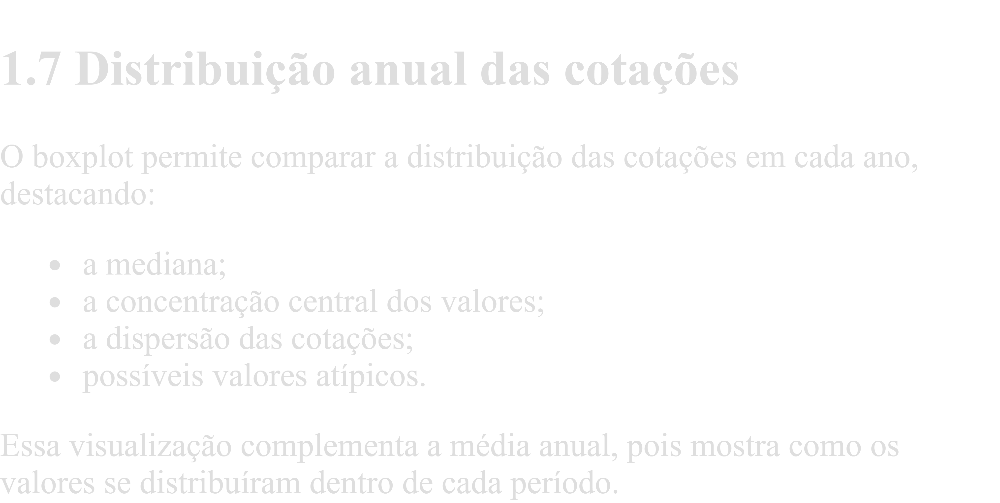

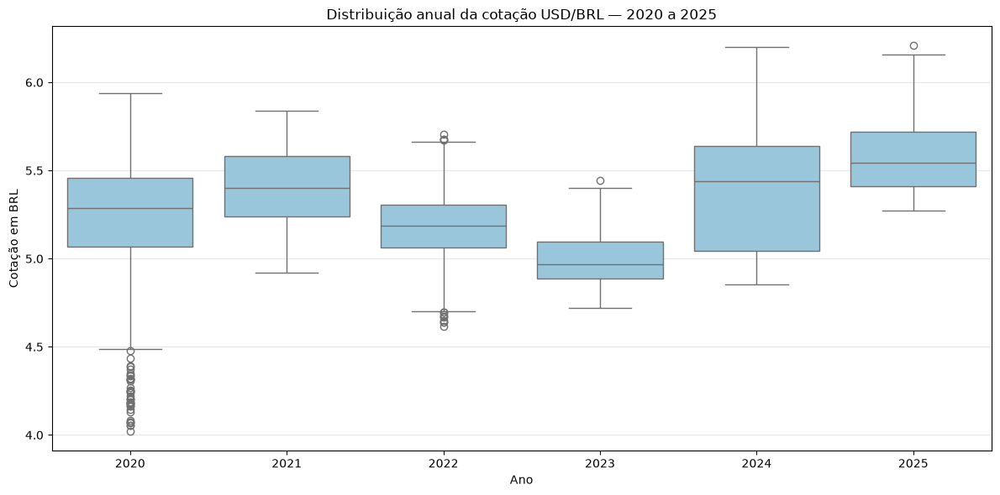

In [29]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_dolar_anual_base,
    x="ano",
    y="valor",
    color="#8ecae6"
)

plt.title("Distribuição anual da cotação USD/BRL — 2020 a 2025")
plt.xlabel("Ano")
plt.ylabel("Cotação em BRL")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [30]:
resumo_anual_dolar["amplitude"] = (
    resumo_anual_dolar["maximo"]
    - resumo_anual_dolar["minimo"]
)

amplitude_anual = resumo_anual_dolar[
    ["ano", "minimo", "maximo", "amplitude", "desvio_padrao"]
].copy()

amplitude_anual[
    ["minimo", "maximo", "amplitude", "desvio_padrao"]
] = amplitude_anual[
    ["minimo", "maximo", "amplitude", "desvio_padrao"]
].round(4)

amplitude_anual

,ano,minimo,maximo,amplitude,desvio_padrao
0,2020,4.0213,5.9372,1.9159,0.4700
1,2021,4.9206,5.8397,0.9191,0.2090
2,2022,4.6175,5.7042,1.0867,0.2232
3,2023,4.7202,5.4459,0.7257,0.1487
4,2024,4.8543,6.1991,1.3448,0.3601
5,2025,5.2729,6.2086,0.9357,0.2129


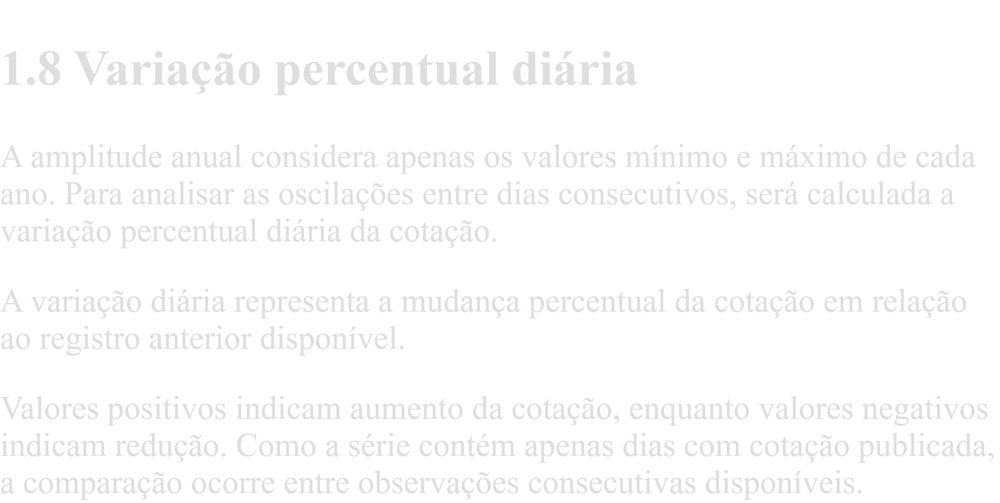

In [31]:
# Criar uma cópia para preservar o DataFrame tratado
df_dolar_variacao = df_dolar.copy()

# Calcular a variação percentual em relação à observação anterior
df_dolar_variacao["variacao_diaria_pct"] = (
    df_dolar_variacao["valor"]
    .pct_change(fill_method=None)
    .mul(100)
)

df_dolar_variacao.head()

,data,valor,variacao_diaria_pct
0,2020-01-02,4.0213,NaN
1,2020-01-03,4.0522,0.768408
2,2020-01-06,4.0554,0.078969
3,2020-01-07,4.0841,0.707698
4,2020-01-08,4.0672,-0.413800


In [32]:
estatisticas_variacao_diaria = (
    df_dolar_variacao["variacao_diaria_pct"]
    .describe()
)

estatisticas_variacao_diaria

count    1506.000000
mean        0.024979
std         0.912384
min        -4.505270
25%        -0.484455
50%         0.000000
75%         0.492357
max         4.482434
Name: variacao_diaria_pct, dtype: float64

In [33]:
maior_alta_diaria = df_dolar_variacao.loc[
    df_dolar_variacao["variacao_diaria_pct"].idxmax()
]

maior_queda_diaria = df_dolar_variacao.loc[
    df_dolar_variacao["variacao_diaria_pct"].idxmin()
]

print("Maior alta diária observada:")
print(f"Data: {maior_alta_diaria['data']:%d/%m/%Y}")
print(f"Cotação: R$ {maior_alta_diaria['valor']:.4f}")
print(
    f"Variação: "
    f"{maior_alta_diaria['variacao_diaria_pct']:.2f}%"
)

print("\nMaior queda diária observada:")
print(f"Data: {maior_queda_diaria['data']:%d/%m/%Y}")
print(f"Cotação: R$ {maior_queda_diaria['valor']:.4f}")
print(
    f"Variação: "
    f"{maior_queda_diaria['variacao_diaria_pct']:.2f}%"
)

Maior alta diária observada:
Data: 12/03/2020
Cotação: R$ 4.8833
Variação: 4.48%

Maior queda diária observada:
Data: 09/11/2020
Cotação: R$ 5.2821
Variação: -4.51%


In [48]:
# Recalcular os registros necessários para o resumo

# Menor e maior cotação do período
registro_minimo = df_dolar.loc[
    df_dolar["valor"].idxmin()
]

registro_maximo = df_dolar.loc[
    df_dolar["valor"].idxmax()
]

# Ano com maior e menor cotação média
ano_maior_media = resumo_anual_dolar.loc[
    resumo_anual_dolar["media"].idxmax()
]

ano_menor_media = resumo_anual_dolar.loc[
    resumo_anual_dolar["media"].idxmin()
]

# Ano com maior e menor volatilidade
ano_maior_volatilidade = volatilidade_anual.loc[
    volatilidade_anual["volatilidade_pct"].idxmax()
]

ano_menor_volatilidade = volatilidade_anual.loc[
    volatilidade_anual["volatilidade_pct"].idxmin()
]

# Criar a tabela consolidada
resumo_eda_dolar = pd.DataFrame({
    "Indicador": [
        "Data inicial",
        "Data final",
        "Quantidade de observações",
        "Cotação média",
        "Mediana",
        "Menor cotação",
        "Data da menor cotação",
        "Maior cotação",
        "Data da maior cotação",
        "Ano com maior média",
        "Maior média anual",
        "Ano com menor média",
        "Menor média anual",
        "Ano com maior volatilidade",
        "Maior volatilidade diária anual",
        "Ano com menor volatilidade",
        "Menor volatilidade diária anual"
    ],
    "Resultado": [
        df_dolar["data"].min().strftime("%d/%m/%Y"),
        df_dolar["data"].max().strftime("%d/%m/%Y"),
        f"{len(df_dolar)}",
        f"R$ {df_dolar['valor'].mean():.4f}",
        f"R$ {df_dolar['valor'].median():.4f}",
        f"R$ {registro_minimo['valor']:.4f}",
        registro_minimo["data"].strftime("%d/%m/%Y"),
        f"R$ {registro_maximo['valor']:.4f}",
        registro_maximo["data"].strftime("%d/%m/%Y"),
        f"{int(ano_maior_media['ano'])}",
        f"R$ {ano_maior_media['media']:.4f}",
        f"{int(ano_menor_media['ano'])}",
        f"R$ {ano_menor_media['media']:.4f}",
        f"{int(ano_maior_volatilidade['ano'])}",
        f"{ano_maior_volatilidade['volatilidade_pct']:.4f}%",
        f"{int(ano_menor_volatilidade['ano'])}",
        f"{ano_menor_volatilidade['volatilidade_pct']:.4f}%"
    ]
})

resumo_eda_dolar

,Indicador,Resultado
0,Data inicial,02/01/2020
1,Data final,31/12/2025
2,Quantidade de observações,1507
3,Cotação média,R$ 5.2827
4,Mediana,R$ 5.2932
5,Menor cotação,R$ 4.0213
6,Data da menor cotação,02/01/2020
7,Maior cotação,R$ 6.2086
8,Data da maior cotação,02/01/2025
9,Ano com maior média,2025


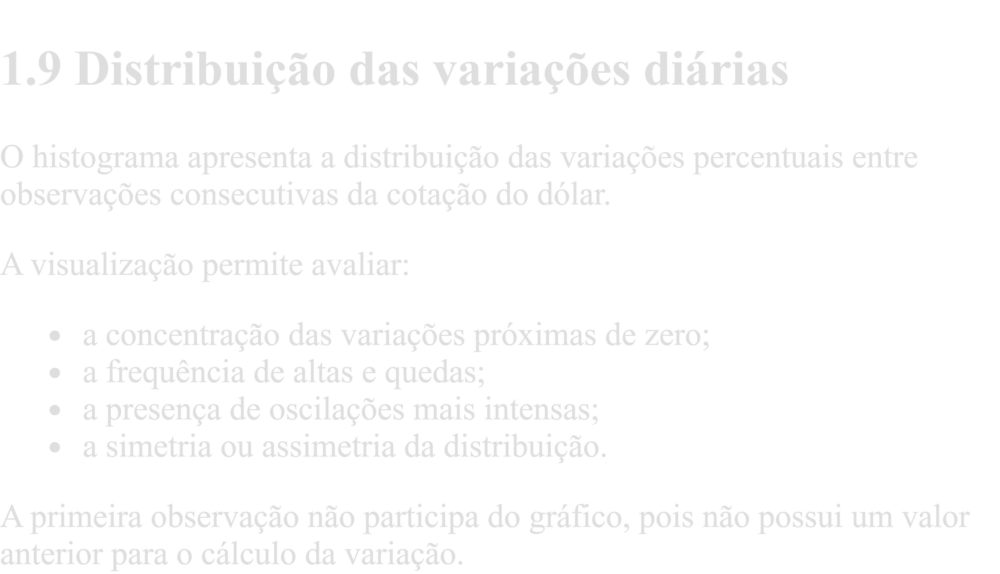

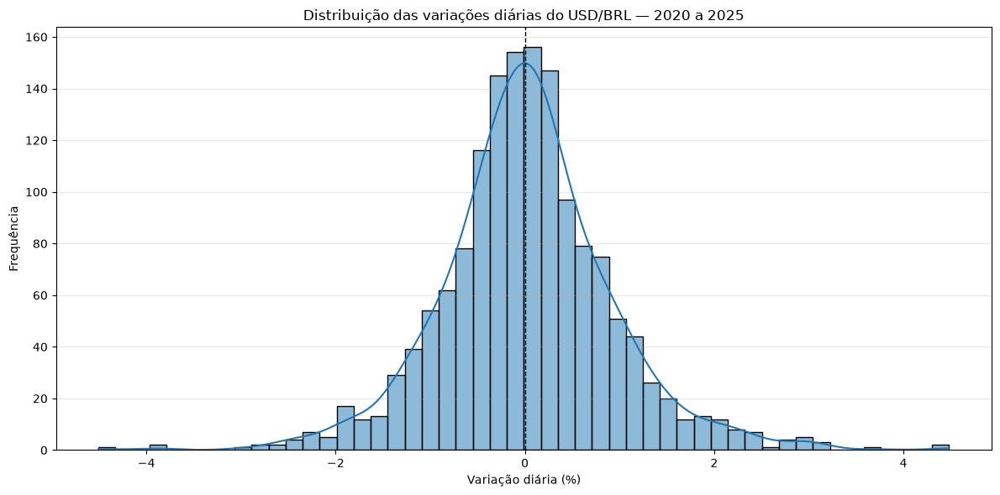

In [34]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_dolar_variacao,
    x="variacao_diaria_pct",
    bins=50,
    kde=True,
    color="#1f77b4"
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Distribuição das variações diárias do USD/BRL — 2020 a 2025")
plt.xlabel("Variação diária (%)")
plt.ylabel("Frequência")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [35]:
quantidade_altas = (
    df_dolar_variacao["variacao_diaria_pct"] > 0
).sum()

quantidade_quedas = (
    df_dolar_variacao["variacao_diaria_pct"] < 0
).sum()

quantidade_sem_variacao = (
    df_dolar_variacao["variacao_diaria_pct"] == 0
).sum()

total_variacoes_validas = (
    df_dolar_variacao["variacao_diaria_pct"]
    .notna()
    .sum()
)

print("Resumo das variações diárias")
print(f"Altas: {quantidade_altas}")
print(f"Quedas: {quantidade_quedas}")
print(f"Sem variação: {quantidade_sem_variacao}")
print(f"Total de variações válidas: {total_variacoes_validas}")

Resumo das variações diárias
Altas: 748
Quedas: 750
Sem variação: 8
Total de variações válidas: 1506


In [36]:
soma_classificacoes = (
    quantidade_altas
    + quantidade_quedas
    + quantidade_sem_variacao
)

print("Soma das classificações:", soma_classificacoes)
print("Total de variações válidas:", total_variacoes_validas)

print(
    "Contagens consistentes:",
    soma_classificacoes == total_variacoes_validas
)

Soma das classificações: 1506
Total de variações válidas: 1506
Contagens consistentes: True


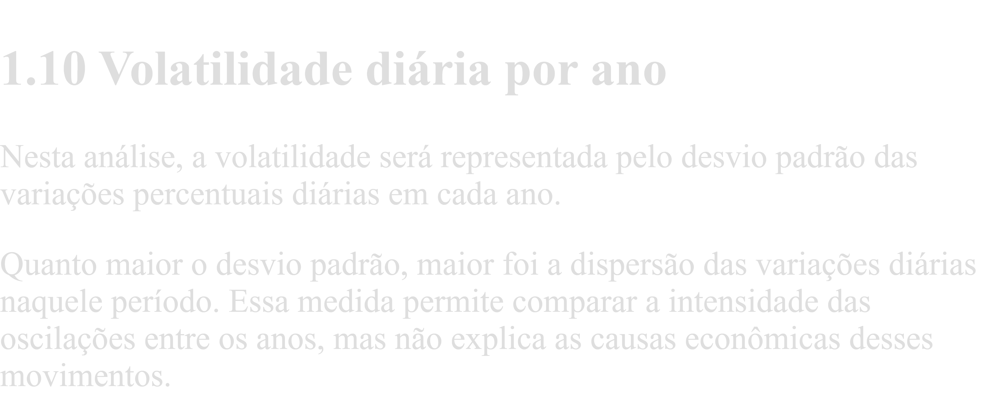

In [37]:
# Criar uma cópia para a análise de volatilidade
df_volatilidade = df_dolar_variacao.copy()

# Extrair o ano da data
df_volatilidade["ano"] = df_volatilidade["data"].dt.year

df_volatilidade.head()

,data,valor,variacao_diaria_pct,ano
0,2020-01-02,4.0213,NaN,2020
1,2020-01-03,4.0522,0.768408,2020
2,2020-01-06,4.0554,0.078969,2020
3,2020-01-07,4.0841,0.707698,2020
4,2020-01-08,4.0672,-0.413800,2020


In [38]:
volatilidade_anual = (
    df_volatilidade
    .groupby("ano")
    .agg(
        observacoes=("variacao_diaria_pct", "count"),
        variacao_media_pct=("variacao_diaria_pct", "mean"),
        volatilidade_pct=("variacao_diaria_pct", "std"),
        menor_variacao_pct=("variacao_diaria_pct", "min"),
        maior_variacao_pct=("variacao_diaria_pct", "max")
    )
    .reset_index()
)

volatilidade_anual

,ano,observacoes,variacao_media_pct,volatilidade_pct,menor_variacao_pct,maior_variacao_pct
0,2020,250,0.110781,1.280976,-4.505270,4.482434
1,2021,251,0.032682,0.928322,-2.868020,3.182505
2,2022,251,-0.021664,1.013967,-3.817556,3.152601
3,2023,249,-0.027329,0.741307,-2.558075,2.425897
4,2024,253,0.099765,0.699772,-1.939423,2.710539
5,2025,252,-0.044756,0.650954,-2.458543,3.049922


In [39]:
volatilidade_anual_exibicao = volatilidade_anual.copy()

colunas_percentuais = [
    "variacao_media_pct",
    "volatilidade_pct",
    "menor_variacao_pct",
    "maior_variacao_pct"
]

volatilidade_anual_exibicao[colunas_percentuais] = (
    volatilidade_anual_exibicao[colunas_percentuais]
    .round(4)
)

volatilidade_anual_exibicao

,ano,observacoes,variacao_media_pct,volatilidade_pct,menor_variacao_pct,maior_variacao_pct
0,2020,250,0.1108,1.2810,-4.5053,4.4824
1,2021,251,0.0327,0.9283,-2.8680,3.1825
2,2022,251,-0.0217,1.0140,-3.8176,3.1526
3,2023,249,-0.0273,0.7413,-2.5581,2.4259
4,2024,253,0.0998,0.6998,-1.9394,2.7105
5,2025,252,-0.0448,0.6510,-2.4585,3.0499


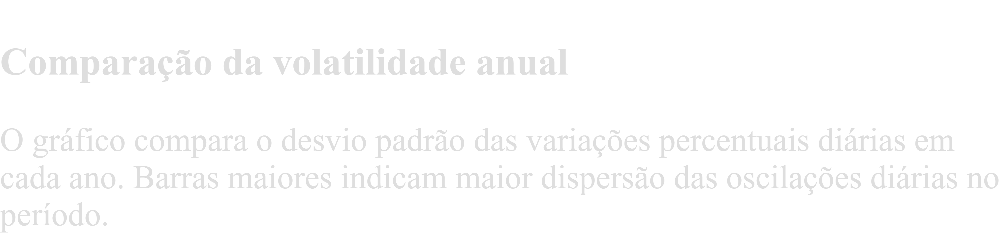

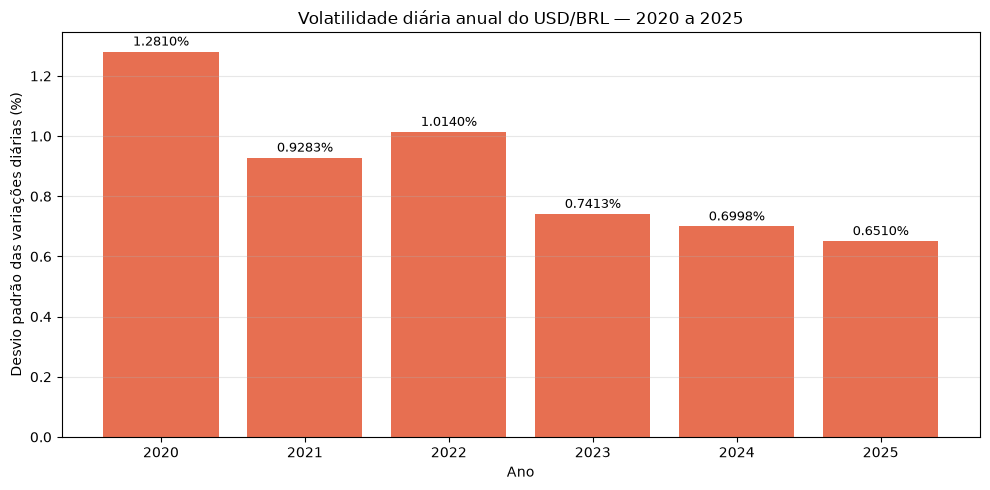

In [40]:
plt.figure(figsize=(10, 5))

barras = plt.bar(
    volatilidade_anual["ano"].astype(str),
    volatilidade_anual["volatilidade_pct"],
    color="#e76f51"
)

for barra, valor in zip(
    barras,
    volatilidade_anual["volatilidade_pct"]
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.01,
        f"{valor:.4f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("Volatilidade diária anual do USD/BRL — 2020 a 2025")
plt.xlabel("Ano")
plt.ylabel("Desvio padrão das variações diárias (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [41]:
ano_maior_volatilidade = volatilidade_anual.loc[
    volatilidade_anual["volatilidade_pct"].idxmax()
]

ano_menor_volatilidade = volatilidade_anual.loc[
    volatilidade_anual["volatilidade_pct"].idxmin()
]

print("Ano com maior volatilidade diária:")
print(f"Ano: {int(ano_maior_volatilidade['ano'])}")
print(
    f"Volatilidade: "
    f"{ano_maior_volatilidade['volatilidade_pct']:.4f}%"
)

print("\nAno com menor volatilidade diária:")
print(f"Ano: {int(ano_menor_volatilidade['ano'])}")
print(
    f"Volatilidade: "
    f"{ano_menor_volatilidade['volatilidade_pct']:.4f}%"
)

Ano com maior volatilidade diária:
Ano: 2020
Volatilidade: 1.2810%

Ano com menor volatilidade diária:
Ano: 2025
Volatilidade: 0.6510%


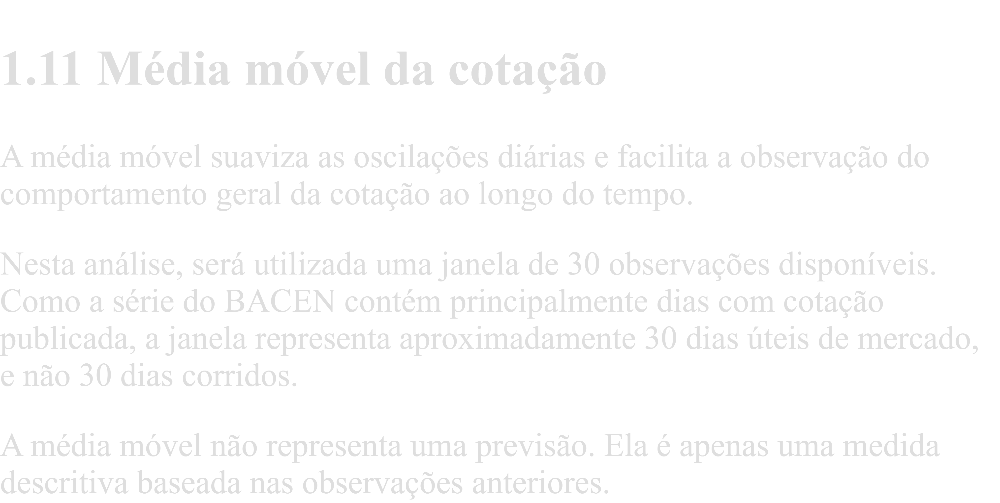

In [42]:
# Criar uma cópia para preservar o DataFrame tratado
df_dolar_media_movel = df_dolar.copy()

# Calcular a média móvel das últimas 30 observações
df_dolar_media_movel["media_movel_30"] = (
    df_dolar_media_movel["valor"]
    .rolling(window=30)
    .mean()
)

df_dolar_media_movel.head(35)

,data,valor,media_movel_30
0,2020-01-02,4.0213,NaN
1,2020-01-03,4.0522,NaN
2,2020-01-06,4.0554,NaN
3,2020-01-07,4.0841,NaN
4,2020-01-08,4.0672,NaN
5,2020-01-09,4.0744,NaN
6,2020-01-10,4.0745,NaN
7,2020-01-13,4.1309,NaN
8,2020-01-14,4.1443,NaN
9,2020-01-15,4.1622,NaN


In [43]:
print(
    "Quantidade de registros da série:",
    len(df_dolar_media_movel)
)

print(
    "Médias móveis calculadas:",
    df_dolar_media_movel["media_movel_30"].notna().sum()
)

print(
    "Registros iniciais sem média móvel:",
    df_dolar_media_movel["media_movel_30"].isna().sum()
)

Quantidade de registros da série: 1507
Médias móveis calculadas: 1478
Registros iniciais sem média móvel: 29


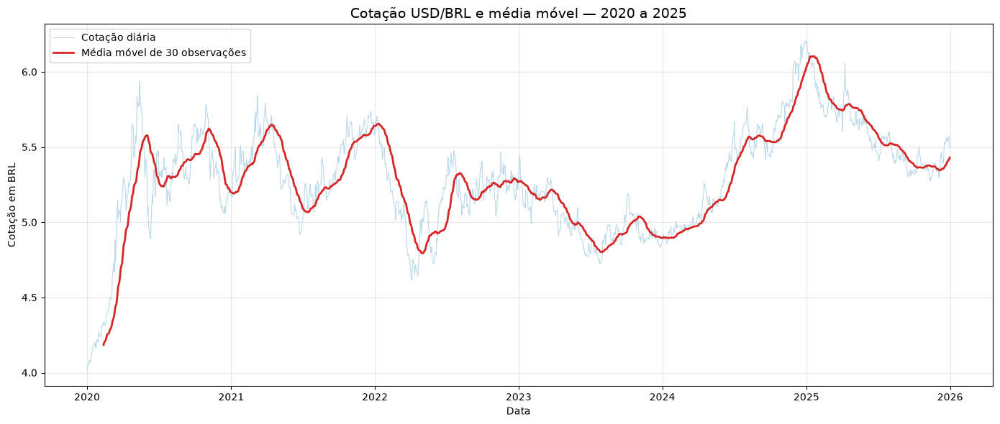

In [44]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_dolar_media_movel["data"],
    df_dolar_media_movel["valor"],
    color="#9ecae1",
    linewidth=0.8,
    alpha=0.7,
    label="Cotação diária"
)

plt.plot(
    df_dolar_media_movel["data"],
    df_dolar_media_movel["media_movel_30"],
    color="#d62728",
    linewidth=2,
    label="Média móvel de 30 observações"
)

plt.title(
    "Cotação USD/BRL e média móvel — 2020 a 2025",
    fontsize=14
)

plt.xlabel("Data")
plt.ylabel("Cotação em BRL")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

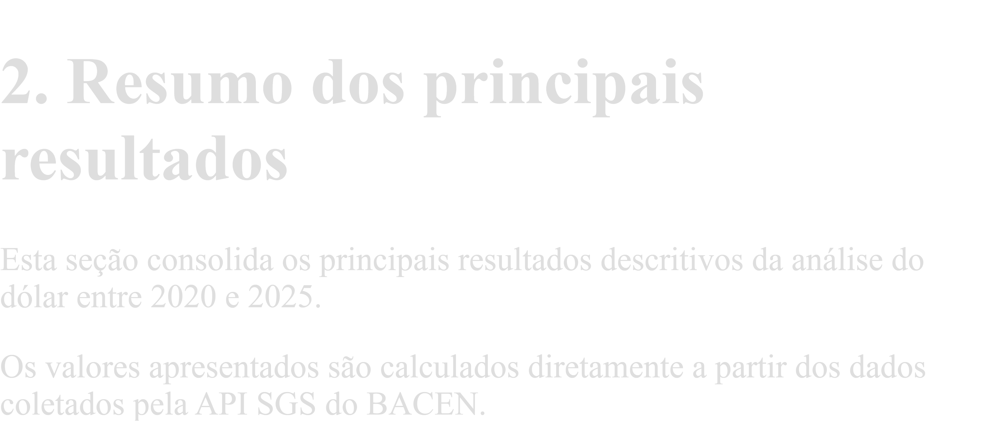

In [49]:
resumo_eda_dolar = pd.DataFrame({
    "Indicador": [
        "Data inicial",
        "Data final",
        "Quantidade de observações",
        "Cotação média",
        "Mediana",
        "Menor cotação",
        "Data da menor cotação",
        "Maior cotação",
        "Data da maior cotação",
        "Ano com maior média",
        "Maior média anual",
        "Ano com menor média",
        "Menor média anual",
        "Ano com maior volatilidade",
        "Maior volatilidade diária anual",
        "Ano com menor volatilidade",
        "Menor volatilidade diária anual"
    ],
    "Resultado": [
        df_dolar["data"].min().strftime("%d/%m/%Y"),
        df_dolar["data"].max().strftime("%d/%m/%Y"),
        f"{len(df_dolar)}",
        f"R$ {df_dolar['valor'].mean():.4f}",
        f"R$ {df_dolar['valor'].median():.4f}",
        f"R$ {registro_minimo['valor']:.4f}",
        registro_minimo["data"].strftime("%d/%m/%Y"),
        f"R$ {registro_maximo['valor']:.4f}",
        registro_maximo["data"].strftime("%d/%m/%Y"),
        f"{int(ano_maior_media['ano'])}",
        f"R$ {ano_maior_media['media']:.4f}",
        f"{int(ano_menor_media['ano'])}",
        f"R$ {ano_menor_media['media']:.4f}",
        f"{int(ano_maior_volatilidade['ano'])}",
        f"{ano_maior_volatilidade['volatilidade_pct']:.4f}%",
        f"{int(ano_menor_volatilidade['ano'])}",
        f"{ano_menor_volatilidade['volatilidade_pct']:.4f}%"
    ]
})

resumo_eda_dolar

,Indicador,Resultado
0,Data inicial,02/01/2020
1,Data final,31/12/2025
2,Quantidade de observações,1507
3,Cotação média,R$ 5.2827
4,Mediana,R$ 5.2932
5,Menor cotação,R$ 4.0213
6,Data da menor cotação,02/01/2020
7,Maior cotação,R$ 6.2086
8,Data da maior cotação,02/01/2025
9,Ano com maior média,2025


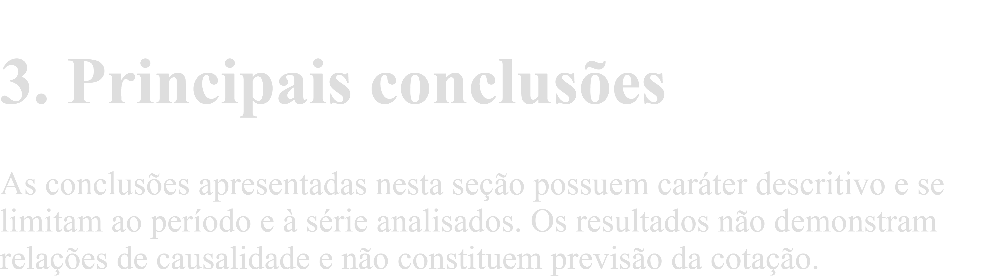

In [50]:
print("PRINCIPAIS RESULTADOS DO EDA\n")

print(
    f"1. O conjunto analisado compreende o período de "
    f"{df_dolar['data'].min():%d/%m/%Y} a "
    f"{df_dolar['data'].max():%d/%m/%Y}, "
    f"com {len(df_dolar)} observações."
)

print(
    f"\n2. A cotação média do período foi de "
    f"R$ {df_dolar['valor'].mean():.4f}, "
    f"enquanto a mediana foi de "
    f"R$ {df_dolar['valor'].median():.4f}."
)

print(
    f"\n3. A menor cotação observada foi de "
    f"R$ {registro_minimo['valor']:.4f}, "
    f"registrada em {registro_minimo['data']:%d/%m/%Y}."
)

print(
    f"\n4. A maior cotação observada foi de "
    f"R$ {registro_maximo['valor']:.4f}, "
    f"registrada em {registro_maximo['data']:%d/%m/%Y}."
)

print(
    f"\n5. O ano com a maior cotação média foi "
    f"{int(ano_maior_media['ano'])}, "
    f"com média de R$ {ano_maior_media['media']:.4f}."
)

print(
    f"\n6. O ano com a menor cotação média foi "
    f"{int(ano_menor_media['ano'])}, "
    f"com média de R$ {ano_menor_media['media']:.4f}."
)

print(
    f"\n7. O ano com maior volatilidade diária foi "
    f"{int(ano_maior_volatilidade['ano'])}, "
    f"com desvio padrão das variações de "
    f"{ano_maior_volatilidade['volatilidade_pct']:.4f}%."
)

print(
    f"\n8. O ano com menor volatilidade diária foi "
    f"{int(ano_menor_volatilidade['ano'])}, "
    f"com desvio padrão das variações de "
    f"{ano_menor_volatilidade['volatilidade_pct']:.4f}%."
)

print(
    "\n9. A média móvel de 30 observações suavizou as "
    "oscilações diárias e facilitou a visualização do "
    "comportamento geral da série."
)

PRINCIPAIS RESULTADOS DO EDA

1. O conjunto analisado compreende o período de 02/01/2020 a 31/12/2025, com 1507 observações.

2. A cotação média do período foi de R$ 5.2827, enquanto a mediana foi de R$ 5.2932.

3. A menor cotação observada foi de R$ 4.0213, registrada em 02/01/2020.

4. A maior cotação observada foi de R$ 6.2086, registrada em 02/01/2025.

5. O ano com a maior cotação média foi 2025, com média de R$ 5.5855.

6. O ano com a menor cotação média foi 2023, com média de R$ 4.9953.

7. O ano com maior volatilidade diária foi 2020, com desvio padrão das variações de 1.2810%.

8. O ano com menor volatilidade diária foi 2025, com desvio padrão das variações de 0.6510%.

9. A média móvel de 30 observações suavizou as oscilações diárias e facilitou a visualização do comportamento geral da série.


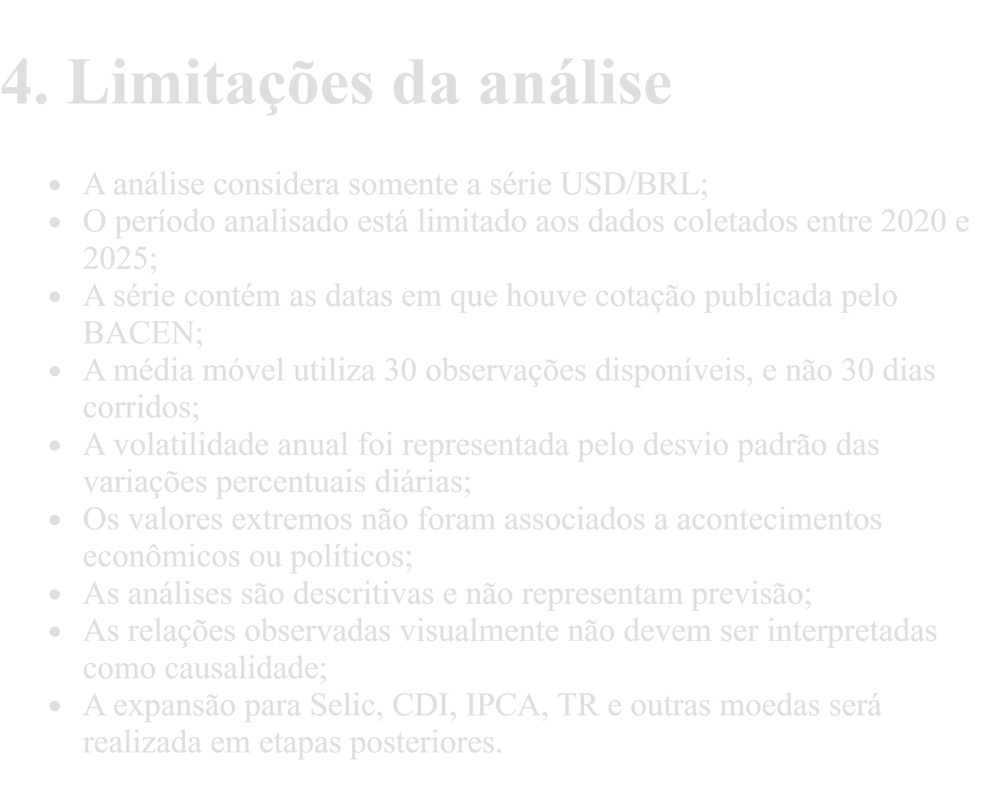

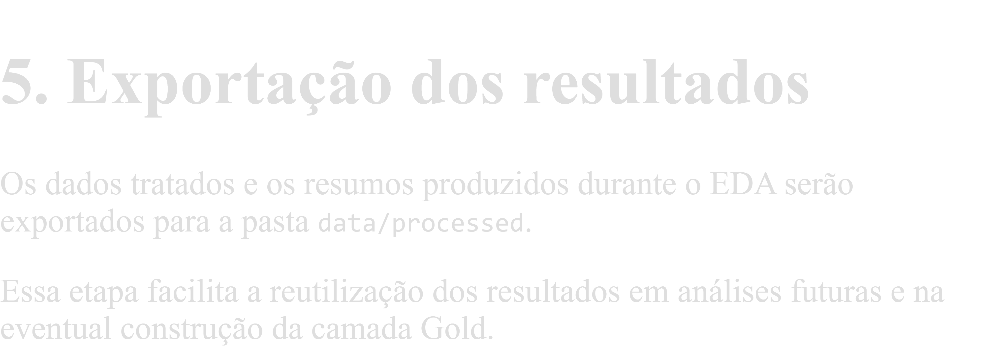

In [51]:
from pathlib import Path

# Definir a pasta de saída
pasta_processados = Path("../data/processed")

# Criar a pasta, caso ainda não exista
pasta_processados.mkdir(parents=True, exist_ok=True)

# Exportar os dados tratados
df_dolar.to_csv(
    pasta_processados / "dolar_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar o resumo anual
resumo_anual_dolar.to_csv(
    pasta_processados / "resumo_anual_dolar_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar a volatilidade anual
volatilidade_anual.to_csv(
    pasta_processados / "volatilidade_anual_dolar_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar o resumo consolidado do EDA
resumo_eda_dolar.to_csv(
    pasta_processados / "resumo_eda_dolar_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos exportados com sucesso!")

Arquivos exportados com sucesso!


In [52]:
arquivos_exportados = sorted(pasta_processados.glob("*.csv"))

print("Arquivos encontrados:")

for arquivo in arquivos_exportados:
    print(f"- {arquivo.name}")

Arquivos encontrados:
- dolar_2020_2025.csv
- resumo_anual_dolar_2020_2025.csv
- resumo_eda_dolar_2020_2025.csv
- volatilidade_anual_dolar_2020_2025.csv
